# TRABALHO 3 — PARTES 3 E 4: Regressão Logística e SVM — RESOLVIDO

Resolução dos exercícios de `TRABALHO_3_RegressãoLogística_SVM.ipynb`.
O enunciado reúne a Parte 3 (Regressão Logística) e a Parte 4 (SVM).
Mantemos a sequência das partes anteriores: leitura, pré-processamento,
treinamento, previsões, métricas e interpretação dos resultados.

**Relação com as partes anteriores:** a Parte 1 utiliza `LabelEncoder` por
atributo, salva `risco_credito.pkl` e treina `GaussianNB` nos 14 registros.
A Parte 2 reutiliza esse arquivo para a árvore didática e carrega `credit.pkl`
para avaliar árvores e florestas em 1.500 exemplos de treino e 500 de teste.
Aqui reutilizamos os mesmos arquivos e a mesma ordem dos atributos.
A comparação do Naïve Bayes na Credit Data exige um novo treinamento nessa base:
as previsões dos dois clientes da Parte 1 não são uma medida de acurácia.

## Bibliotecas e localização dos arquivos

Execute todas as células em ordem. Os caminhos funcionam a partir da raiz do
repositório, de `fase3-TrabalhoIA` ou da pasta de qualquer uma das partes.
São necessárias as dependências de `../requirements.txt`.

In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib

if '__file__' in globals():
    matplotlib.use('Agg')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, precision_score, recall_score, f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC

inicio = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
for ancestral in [inicio, *inicio.parents]:
    candidatos = [ancestral, ancestral / 'fase3-TrabalhoIA']
    pasta_projeto = next((p for p in candidatos if
        (p / 'Parte-1/risco_credito.pkl').is_file() and
        (p / 'Parte-2/credit.pkl').is_file()), None)
    if pasta_projeto is not None:
        break
else:
    raise FileNotFoundError('Não foi encontrada a pasta fase3-TrabalhoIA com as bases das partes 1 e 2.')

pasta_saida = pasta_projeto / 'Parte-3'
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Pasta do projeto:', pasta_projeto)

Python: 3.13.6
NumPy: 2.5.3 | pandas: 3.1.1 | scikit-learn: 1.9.1
Pasta do projeto: C:\programas\IA_Aplicada\fase3-TrabalhoIA


# PARTE 3 — Regressão Logística
## 1 e 2 — Carregar risco_credito.pkl, aplicar o Encoder e remover moderado

Os atributos do Pickle já foram codificados na Parte 1. Reconstituímos os
codificadores a partir do CSV para mostrar os códigos e transformar os novos
clientes com o mesmo mapeamento. Conferimos a correspondência com o Pickle.
Excluímos `moderado` usando uma máscara, aplicada simultaneamente a X e y.
Restam 11 registros: 6 de risco alto e 5 de risco baixo.
Também codificamos a classe binária: `alto = 0`, `baixo = 1`.

In [2]:
with (pasta_projeto / 'Parte-1/risco_credito.pkl').open('rb') as arquivo:
    X_risco_credito, y_risco_credito = pickle.load(arquivo)

X_risco_credito = np.asarray(X_risco_credito, dtype=int)
y_risco_credito = np.asarray(y_risco_credito, dtype=str)
dataset_risco_credito = pd.read_csv(pasta_projeto / 'Parte-1/risco_credito.csv')
atributos_risco = ['historia', 'divida', 'garantias', 'renda']
encoders = {}
X_conferencia = np.empty_like(X_risco_credito)
for i, atributo in enumerate(atributos_risco):
    encoder = LabelEncoder()
    X_conferencia[:, i] = encoder.fit_transform(dataset_risco_credito[atributo])
    encoders[atributo] = encoder
    print(atributo, dict(zip(encoder.classes_, map(int, encoder.transform(encoder.classes_)))))

np.testing.assert_array_equal(X_conferencia, X_risco_credito)
np.testing.assert_array_equal(dataset_risco_credito['risco'].to_numpy(dtype=str), y_risco_credito)
mascara_binaria = y_risco_credito != 'moderado'
X_risco_binario = X_risco_credito[mascara_binaria]
encoder_classe = LabelEncoder()
y_risco_binario = encoder_classe.fit_transform(y_risco_credito[mascara_binaria])
assert X_risco_credito.shape == (14, 4) and X_risco_binario.shape == (11, 4)

print('Classes binárias:', dict(zip(encoder_classe.classes_, map(int, encoder_classe.transform(encoder_classe.classes_)))))
dados_binarios = pd.DataFrame(X_risco_binario, columns=atributos_risco)
dados_binarios['risco'] = encoder_classe.inverse_transform(y_risco_binario)
display(dados_binarios)
display(dados_binarios['risco'].value_counts().to_frame('quantidade'))

historia {'boa': 0, 'desconhecida': 1, 'ruim': 2}
divida {'alta': 0, 'baixa': 1}
garantias {'adequada': 0, 'nenhuma': 1}
renda {'0_15': 0, '15_35': 1, 'acima_35': 2}
Classes binárias: {np.str_('alto'): 0, np.str_('baixo'): 1}


,historia,divida,garantias,renda,risco
0,2,0,1,0,alto
1,1,0,1,1,alto
2,1,1,1,2,alto
3,1,1,1,2,baixo
4,1,1,0,2,baixo
5,2,1,1,0,alto
6,0,1,1,2,baixo
7,0,0,0,2,baixo
8,0,0,1,0,alto
9,0,0,1,2,baixo


,quantidade
risco,
alto,6
baixo,5


## 3, 4 e 5 — Treinar com random_state=1 e obter intercept_ e coef_

A Regressão Logística estima `P(baixo) = 1 / (1 + exp(-z))`, em que
`z = B0 + B1*historia + B2*divida + B3*garantias + B4*renda`.
Mantemos o solver `lbfgs`, C=1 e a tolerância padrão; `max_iter=1000` apenas
aumenta o limite de iterações. Os valores de referência do enunciado são
comparados aos valores efetivamente calculados. Pequenas diferenças podem
ocorrer conforme a versão do solver e sua tolerância numérica.
A codificação de categorias é mantida para reproduzir o exercício; os
coeficientes não demonstram relações causais nem uma ordem natural entre
todas as categorias.

In [3]:
logistica_risco = LogisticRegression(random_state=1, solver='lbfgs', C=1.0, max_iter=1000)
logistica_risco.fit(X_risco_binario, y_risco_binario)
print('B0 (intercept_):', logistica_risco.intercept_)
print('B1 a B4 (coef_):', logistica_risco.coef_)
print('Classes do modelo:', logistica_risco.classes_)

referencia = np.array([-0.80828993, -0.76704533, 0.23906678, -0.47976059, 1.12186218])
calculado = np.r_[logistica_risco.intercept_, logistica_risco.coef_.ravel()]
display(pd.DataFrame({
    'parametro': ['B0', *atributos_risco],
    'referencia_enunciado': referencia,
    'calculado': calculado,
    'diferenca_absoluta': np.abs(calculado - referencia),
}))

B0 (intercept_): [-0.80855152]
B1 a B4 (coef_): [[-0.76706797  0.23921064 -0.47989768  1.12196145]]
Classes do modelo: [0 1]


,parametro,referencia_enunciado,calculado,diferenca_absoluta
0,B0,-0.808290,-0.808552,0.000262
1,historia,-0.767045,-0.767068,0.000023
2,divida,0.239067,0.239211,0.000144
3,garantias,-0.479761,-0.479898,0.000137
4,renda,1.121862,1.121961,0.000099


## 6 — Prever os dois clientes solicitados

a) História boa, dívida alta, nenhuma garantia, renda acima de 35.
b) História ruim, dívida alta, garantia adequada, renda de 0 a 15.
O resultado esperado é, respectivamente, `baixo` e `alto`.

In [4]:
clientes_texto = pd.DataFrame([
    ['boa', 'alta', 'nenhuma', 'acima_35'],
    ['ruim', 'alta', 'adequada', '0_15'],
], columns=atributos_risco)
novos_clientes = np.column_stack([
    encoders[atributo].transform(clientes_texto[atributo]) for atributo in atributos_risco
])
previsoes_clientes = encoder_classe.inverse_transform(logistica_risco.predict(novos_clientes))
resultado_clientes = clientes_texto.copy()
resultado_clientes['previsao'] = previsoes_clientes
resultado_clientes['P(baixo)'] = logistica_risco.predict_proba(novos_clientes)[:, 1]
display(resultado_clientes)
np.testing.assert_array_equal(previsoes_clientes, ['baixo', 'alto'])

,historia,divida,garantias,renda,previsao,P(baixo)
0,boa,alta,nenhuma,acima_35,baixo,0.722215
1,ruim,alta,adequada,0_15,alto,0.087649


## 7 — Regressão Logística na base Credit Data: taxa de acerto

Carregamos a mesma separação de treino e teste da Parte 2, sem embaralhar ou
refazer a divisão. Os atributos `income`, `age` e `loan` já estão em escala
padronizada no arquivo fornecido; não aplicamos outro Encoder nem outro scaler.
O código que produziu esse pré-processamento não acompanha `credit.pkl`, então
não é possível confirmar se a padronização original usou apenas o treino.
Em uma preparação a partir dos dados brutos, o scaler deve ser ajustado apenas
no treino e dentro de cada dobra da validação cruzada.
Aqui, `0 = paga` e `1 = não paga` (classe positiva).

In [5]:
with (pasta_projeto / 'Parte-2/credit.pkl').open('rb') as arquivo:
    X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(arquivo)

X_credit_treinamento = np.asarray(X_credit_treinamento, dtype=float)
X_credit_teste = np.asarray(X_credit_teste, dtype=float)
y_credit_treinamento = np.asarray(y_credit_treinamento, dtype=int)
y_credit_teste = np.asarray(y_credit_teste, dtype=int)
assert X_credit_treinamento.shape == (1500, 3) and X_credit_teste.shape == (500, 3)
print('X treino:', X_credit_treinamento.shape, '| y treino:', y_credit_treinamento.shape)
print('X teste:', X_credit_teste.shape, '| y teste:', y_credit_teste.shape)
display(pd.DataFrame({
    'atributo': ['income', 'age', 'loan'],
    'media_treino': X_credit_treinamento.mean(axis=0),
    'desvio_treino': X_credit_treinamento.std(axis=0),
}))
print('Distribuição das classes no teste:')
display(pd.Series(y_credit_teste).value_counts().sort_index().rename_axis('classe').to_frame('quantidade'))

def metricas_modelo(nome, previsoes):
    vn, fp, fn, vp = confusion_matrix(y_credit_teste, previsoes, labels=[0, 1]).ravel()
    return {
        'modelo': nome, 'acuracia': accuracy_score(y_credit_teste, previsoes),
        'precisao_1': precision_score(y_credit_teste, previsoes, zero_division=0),
        'recall_1': recall_score(y_credit_teste, previsoes, zero_division=0),
        'f1_1': f1_score(y_credit_teste, previsoes, zero_division=0),
        'VN': int(vn), 'FP': int(fp), 'FN': int(fn), 'VP': int(vp),
    }

def relatorio_modelo(nome, previsoes):
    medidas = metricas_modelo(nome, previsoes)
    print(f"{nome}: acurácia = {medidas['acuracia']:.4f} ({medidas['acuracia']:.2%})")
    print('Matriz [[VN, FP], [FN, VP]]:')
    print(confusion_matrix(y_credit_teste, previsoes, labels=[0, 1]))
    print(f"Não pagantes encontrados: {medidas['VP']}; não pagantes previstos como pagantes: {medidas['FN']}.")
    print(classification_report(y_credit_teste, previsoes, labels=[0, 1],
        target_names=['Paga (0)', 'Não paga (1)'], digits=4, zero_division=0))

logistica_credit = LogisticRegression(random_state=1, max_iter=1000)
logistica_credit.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_logistica = logistica_credit.predict(X_credit_teste)
display(pd.DataFrame({'real': y_credit_teste, 'previsao': previsoes_logistica}).head(20))
relatorio_modelo('Regressão Logística', previsoes_logistica)

X treino: (1500, 3) | y treino: (1500,)
X teste: (500, 3) | y teste: (500,)


,atributo,media_treino,desvio_treino
0,income,0.012726,0.998850
1,age,-0.002513,0.991328
2,loan,0.014762,0.999907


Distribuição das classes no teste:


,quantidade
classe,
0,436
1,64


,real,previsao
0,1,1
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,1
9,0,0


Regressão Logística: acurácia = 0.9460 (94.60%)
Matriz [[VN, FP], [FN, VP]]:
[[423  13]
 [ 14  50]]
Não pagantes encontrados: 50; não pagantes previstos como pagantes: 14.
              precision    recall  f1-score   support

    Paga (0)     0.9680    0.9702    0.9691       436
Não paga (1)     0.7937    0.7812    0.7874        64

    accuracy                         0.9460       500
   macro avg     0.8808    0.8757    0.8782       500
weighted avg     0.9457    0.9460    0.9458       500



## 8 — Comparar Regressão Logística, Naïve Bayes e Random Forest

Recalculamos todos os modelos na mesma Credit Data. As florestas repetem os
parâmetros da Parte 2: `criterion='entropy'`, `random_state=0`, 10 e 40 árvores.
As colunas de precisão, recall e F1 referem-se à classe **não paga (1)**.
Precisão = VP/(VP+FP); recall = VP/(VP+FN); acurácia = (VN+VP)/total.
Uma acurácia alta pode esconder falhas na classe minoritária: prever todos
como pagantes já acertaria 436 dos 500 exemplos (87,2%).

In [6]:
modelos_anteriores = {
    'Naïve Bayes': GaussianNB(),
    'Random Forest (10)': RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0),
    'Random Forest (40)': RandomForestClassifier(n_estimators=40, criterion='entropy', random_state=0),
}
previsoes_anteriores = {}
for nome, modelo in modelos_anteriores.items():
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    previsoes_anteriores[nome] = modelo.predict(X_credit_teste)
    relatorio_modelo(nome, previsoes_anteriores[nome])

comparacao_logistica = pd.DataFrame([
    metricas_modelo('Regressão Logística', previsoes_logistica),
    *[metricas_modelo(nome, p) for nome, p in previsoes_anteriores.items()],
]).set_index('modelo')
display(comparacao_logistica)

Naïve Bayes: acurácia = 0.9380 (93.80%)
Matriz [[VN, FP], [FN, VP]]:
[[428   8]
 [ 23  41]]
Não pagantes encontrados: 41; não pagantes previstos como pagantes: 23.
              precision    recall  f1-score   support

    Paga (0)     0.9490    0.9817    0.9651       436
Não paga (1)     0.8367    0.6406    0.7257        64

    accuracy                         0.9380       500
   macro avg     0.8929    0.8111    0.8454       500
weighted avg     0.9346    0.9380    0.9344       500

Random Forest (10): acurácia = 0.9680 (96.80%)
Matriz [[VN, FP], [FN, VP]]:
[[432   4]
 [ 12  52]]
Não pagantes encontrados: 52; não pagantes previstos como pagantes: 12.
              precision    recall  f1-score   support

    Paga (0)     0.9730    0.9908    0.9818       436
Não paga (1)     0.9286    0.8125    0.8667        64

    accuracy                         0.9680       500
   macro avg     0.9508    0.9017    0.9242       500
weighted avg     0.9673    0.9680    0.9671       500



Random Forest (40): acurácia = 0.9840 (98.40%)
Matriz [[VN, FP], [FN, VP]]:
[[433   3]
 [  5  59]]
Não pagantes encontrados: 59; não pagantes previstos como pagantes: 5.
              precision    recall  f1-score   support

    Paga (0)     0.9886    0.9931    0.9908       436
Não paga (1)     0.9516    0.9219    0.9365        64

    accuracy                         0.9840       500
   macro avg     0.9701    0.9575    0.9637       500
weighted avg     0.9839    0.9840    0.9839       500



,acuracia,precisao_1,recall_1,f1_1,VN,FP,FN,VP
modelo,,,,,,,,
Regressão Logística,0.946,0.793651,0.781250,0.787402,423,13,14,50
Naïve Bayes,0.938,0.836735,0.640625,0.725664,428,8,23,41
Random Forest (10),0.968,0.928571,0.812500,0.866667,432,4,12,52
Random Forest (40),0.984,0.951613,0.921875,0.936508,433,3,5,59


# PARTE 4 — SVM
## 1, 2 e 3 — Kernel linear, C=1.0 e random_state=1

O enunciado prevê acurácia de 0,946. Calculamos a taxa efetiva com
`accuracy_score`, sem alterar os dados ou as previsões para atingir a referência.

In [7]:
svm_linear = SVC(kernel='linear', C=1.0, random_state=1)
svm_linear.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_linear = svm_linear.predict(X_credit_teste)
acuracia_linear = accuracy_score(y_credit_teste, previsoes_linear)
relatorio_modelo('SVM linear (C=1)', previsoes_linear)
print('Referência do enunciado: 0.946 | diferença:', round(acuracia_linear - 0.946, 6))

SVM linear (C=1): acurácia = 0.9460 (94.60%)
Matriz [[VN, FP], [FN, VP]]:


[[422  14]
 [ 13  51]]
Não pagantes encontrados: 51; não pagantes previstos como pagantes: 13.
              precision    recall  f1-score   support

    Paga (0)     0.9701    0.9679    0.9690       436
Não paga (1)     0.7846    0.7969    0.7907        64

    accuracy                         0.9460       500
   macro avg     0.8774    0.8824    0.8798       500
weighted avg     0.9464    0.9460    0.9462       500

Referência do enunciado: 0.946 | diferença: 0.0


## 4 — Testar os kernels polinomial, sigmoide e RBF

Para responder ao exercício, mostramos o resultado de teste de cada kernel.
Para **escolher** o kernel, usamos a média de acurácia em validação cruzada
estratificada de cinco dobras, somente nos 1.500 exemplos de treino.
Usamos as mesmas dobras em todas as comparações (`shuffle=True`, `random_state=1`).
O teste permanece fora do `fit` e da seleção de hiperparâmetros.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
modelos_kernels = {}
resultados_kernels = []
for kernel in ['linear', 'poly', 'sigmoid', 'rbf']:
    modelo = SVC(kernel=kernel, C=1.0, random_state=1)
    notas = cross_val_score(modelo, X_credit_treinamento, y_credit_treinamento,
                            cv=cv, scoring='accuracy', n_jobs=1)
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    modelos_kernels[kernel] = modelo
    resultados_kernels.append({
        'kernel': kernel, 'acuracia_cv': notas.mean(), 'desvio_cv': notas.std(),
        'acuracia_teste': accuracy_score(y_credit_teste, modelo.predict(X_credit_teste)),
    })
tabela_kernels = pd.DataFrame(resultados_kernels).sort_values('acuracia_cv', ascending=False)
display(tabela_kernels)
melhor_kernel = tabela_kernels.iloc[0]['kernel']
print('Melhor kernel pela validação cruzada:', melhor_kernel)

,kernel,acuracia_cv,desvio_cv,acuracia_teste
3,rbf,0.978000,0.007483,0.982
1,poly,0.954667,0.010456,0.968
0,linear,0.946000,0.008000,0.946
2,sigmoid,0.850667,0.018062,0.838


Melhor kernel pela validação cruzada: rbf


## 5 — Aumentar C no melhor kernel

C maior penaliza mais os erros de treinamento e pode produzir uma fronteira
mais ajustada aos dados. Isso pode melhorar ou piorar a generalização.
Comparamos C=1, 10 e 100; escolhemos pela média de validação, com desempate
a favor do menor C (ordem dos candidatos).

In [9]:
resultados_c = []
modelos_c = {}
for valor_c in [1.0, 10.0, 100.0]:
    modelo = SVC(kernel=melhor_kernel, C=valor_c, random_state=1)
    notas = cross_val_score(modelo, X_credit_treinamento, y_credit_treinamento,
                            cv=cv, scoring='accuracy', n_jobs=1)
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    modelos_c[valor_c] = modelo
    resultados_c.append({
        'C': valor_c, 'acuracia_cv': notas.mean(), 'desvio_cv': notas.std(),
        'acuracia_teste': accuracy_score(y_credit_teste, modelo.predict(X_credit_teste)),
    })
tabela_c = pd.DataFrame(resultados_c)
display(tabela_c)
melhor_c = float(tabela_c.loc[tabela_c['acuracia_cv'].idxmax(), 'C'])
svm_manual = modelos_c[melhor_c]
previsoes_manual = svm_manual.predict(X_credit_teste)
print('Ajuste manual escolhido por validação:', {'kernel': melhor_kernel, 'C': melhor_c})

,C,acuracia_cv,desvio_cv,acuracia_teste
0,1.0,0.978000,0.007483,0.982
1,10.0,0.984667,0.008589,0.988
2,100.0,0.990667,0.004422,0.990


Ajuste manual escolhido por validação: {'kernel': 'rbf', 'C': 100.0}


## 6 — GridSearchCV: melhores hiperparâmetros e comparação com ajuste manual

A grade inclui todos os kernels e candidatos manuais, além de C=0,1,
valores de gamma e graus polinomiais. Cada dicionário contém apenas parâmetros
relevantes ao kernel correspondente. `scoring='accuracy'` mantém o critério do
enunciado; o recall dos não pagantes será analisado separadamente.
`refit=True` treina a melhor combinação novamente em todo o conjunto de treino.
A escolha usa `best_score_` de validação, sem consultar o conjunto de teste.
A melhor combinação é a melhor **dentro desta grade**, não uma garantia global.
Referência: [documentação oficial do GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

In [10]:
grade = [
    {'kernel': ['linear'], 'C': [0.1, 1.0, 10.0, 100.0]},
    {'kernel': ['rbf', 'sigmoid'], 'C': [0.1, 1.0, 10.0, 100.0],
     'gamma': ['scale', 0.1, 1.0]},
    {'kernel': ['poly'], 'C': [0.1, 1.0, 10.0, 100.0],
     'gamma': ['scale', 0.1, 1.0], 'degree': [2, 3]},
]
busca = GridSearchCV(SVC(random_state=1), param_grid=grade, scoring='accuracy',
                     cv=cv, n_jobs=1, refit=True, return_train_score=True,
                     error_score='raise')
busca.fit(X_credit_treinamento, y_credit_treinamento)
print('Combinações avaliadas:', len(busca.cv_results_['params']))
print('Melhores hiperparâmetros:', busca.best_params_)
print(f'Melhor acurácia média em validação: {busca.best_score_:.4f}')
resultados_grade = pd.DataFrame(busca.cv_results_).sort_values('rank_test_score')
display(resultados_grade[['params', 'mean_train_score', 'mean_test_score',
                         'std_test_score', 'rank_test_score']].head(10))

svm_grid = busca.best_estimator_
previsoes_grid = svm_grid.predict(X_credit_teste)
comparacao_ajustes = pd.DataFrame([
    {'ajuste': 'Manual', 'parametros': {'kernel': melhor_kernel, 'C': melhor_c},
     'acuracia_cv': tabela_c['acuracia_cv'].max(),
     'acuracia_teste': accuracy_score(y_credit_teste, previsoes_manual)},
    {'ajuste': 'GridSearch', 'parametros': busca.best_params_,
     'acuracia_cv': busca.best_score_,
     'acuracia_teste': accuracy_score(y_credit_teste, previsoes_grid)},
])
display(comparacao_ajustes)
melhor_ajuste_cv = 'GridSearch' if busca.best_score_ > tabela_c['acuracia_cv'].max() + 1e-12 else 'Empate'
melhor_ajuste_teste = ('Empate' if np.isclose(comparacao_ajustes.iloc[0]['acuracia_teste'],
    comparacao_ajustes.iloc[1]['acuracia_teste']) else
    comparacao_ajustes.loc[comparacao_ajustes['acuracia_teste'].idxmax(), 'ajuste'])
print('Comparação por validação:', melhor_ajuste_cv)
print('Comparação descritiva no teste:', melhor_ajuste_teste)
relatorio_modelo('SVM GridSearch', previsoes_grid)

Combinações avaliadas: 52
Melhores hiperparâmetros: {'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}
Melhor acurácia média em validação: 0.9907


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
22,"{'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.997333,0.990667,0.004422,1
26,"{'C': 100.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.999167,0.989333,0.004899,2
20,"{'C': 10.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.996167,0.987333,0.009286,3
14,"{'C': 1.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.991167,0.985333,0.009092,4
24,"{'C': 100.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.993667,0.985333,0.009092,4
16,"{'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.993000,0.984667,0.008589,6
18,"{'C': 10.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.984667,0.982000,0.010456,7
10,"{'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.985500,0.978000,0.007483,8
8,"{'C': 0.1, 'gamma': 1.0, 'kernel': 'rbf'}",0.975167,0.972000,0.010022,9
4,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}",0.962500,0.964667,0.010873,10


,ajuste,parametros,acuracia_cv,acuracia_teste
0,Manual,"{'kernel': 'rbf', 'C': 100.0}",0.990667,0.99
1,GridSearch,"{'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.990667,0.99


Comparação por validação: Empate
Comparação descritiva no teste: Empate
SVM GridSearch: acurácia = 0.9900 (99.00%)
Matriz [[VN, FP], [FN, VP]]:
[[435   1]
 [  4  60]]
Não pagantes encontrados: 60; não pagantes previstos como pagantes: 4.
              precision    recall  f1-score   support

    Paga (0)     0.9909    0.9977    0.9943       436
Não paga (1)     0.9836    0.9375    0.9600        64

    accuracy                         0.9900       500
   macro avg     0.9872    0.9676    0.9771       500
weighted avg     0.9900    0.9900    0.9899       500



## Comparação final — Naïve Bayes, Random Forest, Regressão Logística e SVM

Mostramos as duas florestas para preservar a comparação com a Parte 2 e
distinguir a versão inicial da melhor versão daquela atividade.
As matrizes usam linhas = classe real e colunas = previsão: `[[VN, FP], [FN, VP]]`.
FP representa um pagante previsto como não pagante; FN representa um não
pagante previsto como pagante. O segundo erro reduz o recall da classe 1.

,acuracia,precisao_1,recall_1,f1_1,VN,FP,FN,VP
modelo,,,,,,,,
Naïve Bayes,0.938,0.836735,0.640625,0.725664,428,8,23,41
Random Forest (10),0.968,0.928571,0.812500,0.866667,432,4,12,52
Random Forest (40),0.984,0.951613,0.921875,0.936508,433,3,5,59
Regressão Logística,0.946,0.793651,0.781250,0.787402,423,13,14,50
SVM manual,0.990,0.983607,0.937500,0.960000,435,1,4,60
SVM GridSearch,0.990,0.983607,0.937500,0.960000,435,1,4,60


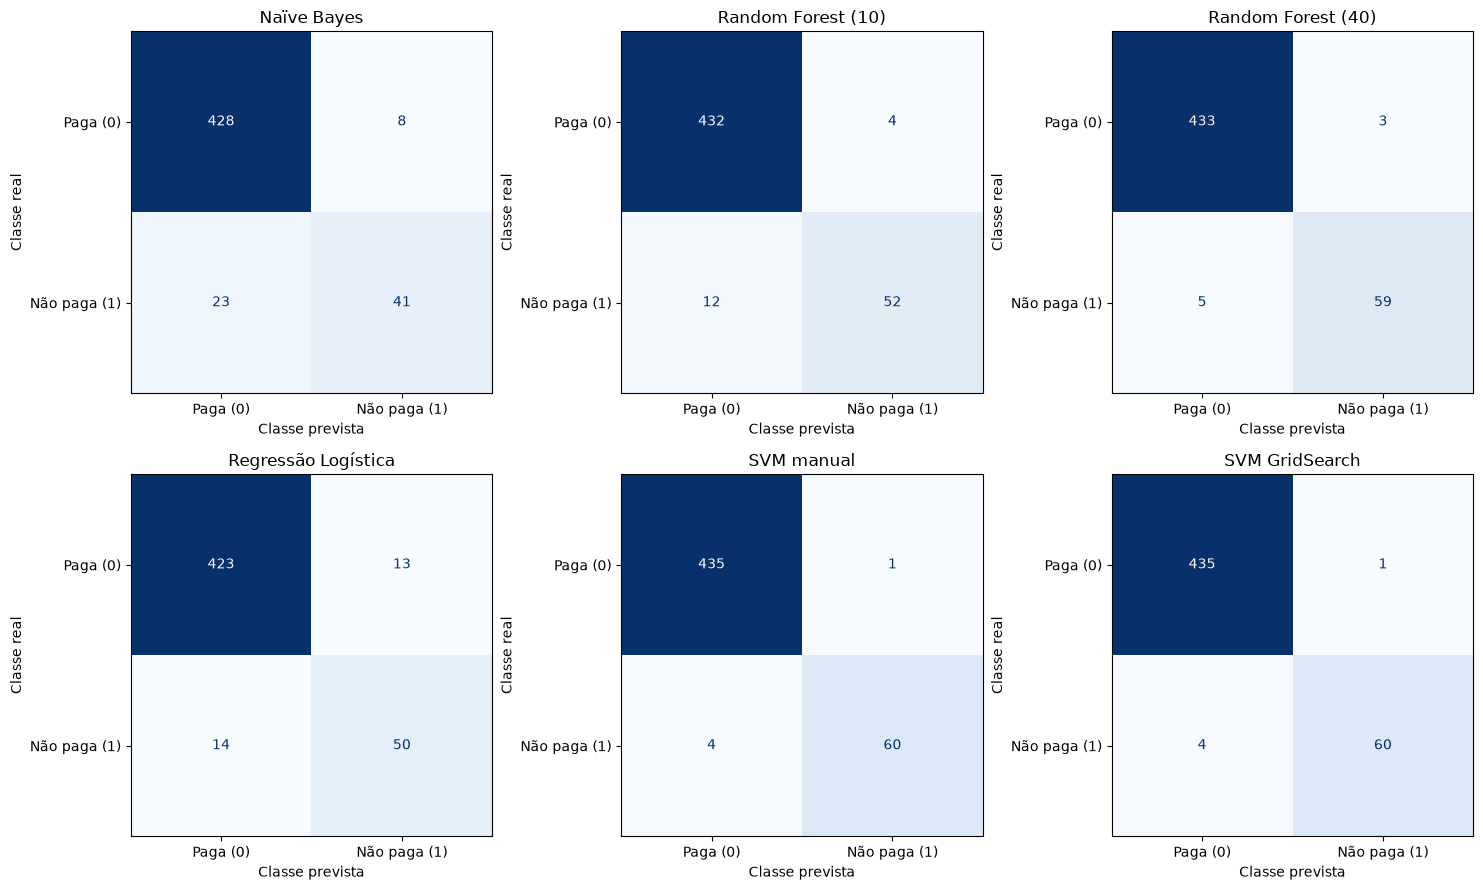

In [11]:
previsoes_finais = {
    'Naïve Bayes': previsoes_anteriores['Naïve Bayes'],
    'Random Forest (10)': previsoes_anteriores['Random Forest (10)'],
    'Random Forest (40)': previsoes_anteriores['Random Forest (40)'],
    'Regressão Logística': previsoes_logistica,
    'SVM manual': previsoes_manual,
    'SVM GridSearch': previsoes_grid,
}
comparacao_final = pd.DataFrame([
    metricas_modelo(nome, p) for nome, p in previsoes_finais.items()
]).set_index('modelo')
display(comparacao_final)
comparacao_final.to_csv(pasta_saida / 'comparacao_modelos_credit.csv', encoding='utf-8-sig')

figura, eixos = plt.subplots(2, 3, figsize=(15, 9))
for eixo, (nome, previsoes) in zip(eixos.ravel(), previsoes_finais.items()):
    matriz = confusion_matrix(y_credit_teste, previsoes, labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['Paga (0)', 'Não paga (1)']).plot(
        ax=eixo, cmap='Blues', values_format='d', colorbar=False)
    eixo.set_title(nome)
    eixo.set_xlabel('Classe prevista')
    eixo.set_ylabel('Classe real')
figura.tight_layout()
figura.savefig(pasta_saida / 'matrizes_confusao_comparacao.png', dpi=140, bbox_inches='tight')
if '__file__' not in globals():
    plt.show()
plt.close(figura)

## Respostas e interpretação calculadas a partir dos resultados

Os textos abaixo usam as métricas obtidas nesta execução. Isso evita copiar
resultados de outra versão da biblioteca ou de outra divisão dos dados.

In [12]:
linha_lr = comparacao_final.loc['Regressão Logística']
print(f"Parte 3, questão 7: Regressão Logística acertou {int(linha_lr['VN'] + linha_lr['VP'])}/500 "
      f"casos ({linha_lr['acuracia']:.2%}).")
for nome in ['Naïve Bayes', 'Random Forest (10)', 'Random Forest (40)']:
    linha = comparacao_final.loc[nome]
    relacao = 'superior' if linha_lr['acuracia'] > linha['acuracia'] else ('igual' if
        np.isclose(linha_lr['acuracia'], linha['acuracia']) else 'inferior')
    print(f"Parte 3, questão 8: a acurácia da logística é {relacao} à de {nome} "
          f"({linha['acuracia']:.2%}). Precisão/recall da classe 1: logística "
          f"{linha_lr['precisao_1']:.2%}/{linha_lr['recall_1']:.2%}; {nome} "
          f"{linha['precisao_1']:.2%}/{linha['recall_1']:.2%}. "
          f"Falsos negativos: {int(linha_lr['FN'])} contra {int(linha['FN'])}.")

print(f'Parte 4, questão 4: melhor kernel pela validação cruzada = {melhor_kernel}.')
for _, linha in tabela_c.iterrows():
    print(f"Parte 4, questão 5: C={linha['C']:g}: validação {linha['acuracia_cv']:.2%}, "
          f"teste {linha['acuracia_teste']:.2%}.")
print('Parte 4, questão 6: melhor combinação da grade:', busca.best_params_)
print('Ajuste manual versus GridSearch: validação =', melhor_ajuste_cv,
      '| teste =', melhor_ajuste_teste)
linha_svm = comparacao_final.loc['SVM GridSearch']
for nome in ['Naïve Bayes', 'Random Forest (10)', 'Random Forest (40)', 'Regressão Logística']:
    linha = comparacao_final.loc[nome]
    relacao = 'superior' if linha_svm['acuracia'] > linha['acuracia'] else ('igual' if
        np.isclose(linha_svm['acuracia'], linha['acuracia']) else 'inferior')
    print(f"Comparação final: a acurácia do SVM GridSearch ({linha_svm['acuracia']:.2%}) "
          f"é {relacao} à de {nome} ({linha['acuracia']:.2%}). "
          f"Precisão/recall da classe 1: SVM {linha_svm['precisao_1']:.2%}/{linha_svm['recall_1']:.2%}; "
          f"{nome} {linha['precisao_1']:.2%}/{linha['recall_1']:.2%}. "
          f"Falsos negativos: {int(linha_svm['FN'])} contra {int(linha['FN'])}.")

Parte 3, questão 7: Regressão Logística acertou 473/500 casos (94.60%).
Parte 3, questão 8: a acurácia da logística é superior à de Naïve Bayes (93.80%). Precisão/recall da classe 1: logística 79.37%/78.12%; Naïve Bayes 83.67%/64.06%. Falsos negativos: 14 contra 23.
Parte 3, questão 8: a acurácia da logística é inferior à de Random Forest (10) (96.80%). Precisão/recall da classe 1: logística 79.37%/78.12%; Random Forest (10) 92.86%/81.25%. Falsos negativos: 14 contra 12.
Parte 3, questão 8: a acurácia da logística é inferior à de Random Forest (40) (98.40%). Precisão/recall da classe 1: logística 79.37%/78.12%; Random Forest (40) 95.16%/92.19%. Falsos negativos: 14 contra 5.
Parte 4, questão 4: melhor kernel pela validação cruzada = rbf.
Parte 4, questão 5: C=1: validação 97.80%, teste 98.20%.
Parte 4, questão 5: C=10: validação 98.47%, teste 98.80%.
Parte 4, questão 5: C=100: validação 99.07%, teste 99.00%.
Parte 4, questão 6: melhor combinação da grade: {'C': 100.0, 'gamma': 'scale',

## Conclusão e limites da comparação

Na execução registrada (scikit-learn 1.9.1), a Regressão Logística reproduziu
as previsões `baixo` e `alto`. O intercepto foi -0,80855152; a maior diferença
absoluta em relação aos parâmetros de referência ficou abaixo de 0,0003.
Na Credit Data, a logística atingiu **94,6%**, acima do Naïve Bayes (**93,8%**),
mas abaixo das florestas de 10 (**96,8%**) e 40 árvores (**98,4%**).
O ganho sobre Bayes envolve uma troca: o recall dos não pagantes subiu de
**64,06% para 78,12%**, mas a precisão caiu de **83,67% para 79,37%**.
Portanto, a logística encontrou mais não pagantes, ao custo de mais falsos
alarmes entre pagantes (13 contra 8).

Com C=1, as acurácias de teste do SVM foram: linear **94,6%**, polinomial
**96,8%**, sigmoide **83,8%** e RBF **98,2%**. O RBF também teve a melhor
média de validação. Aumentar C para 10 e 100 elevou o teste para **98,8%** e
**99,0%**, respectivamente. A grade de 52 combinações confirmou
**kernel='rbf', C=100, gamma='scale'**, com **99,07%** de média de validação.
O ajuste manual e o GridSearch empataram em validação e no teste.

O SVM ajustado acertou **495 de 500 casos**, com matriz `[[435, 1], [4, 60]]`.
Sua precisão de **98,36%** e recall de **93,75%** para não pagantes superaram
os demais modelos desta comparação. Frente à floresta de 40 árvores,
os erros caíram de 8 para 5: falsos positivos de 3 para 1 e falsos negativos
de 5 para 4. Essa vantagem corresponde a somente três exemplos neste teste.

Precisão alta indica que a maioria
dos clientes previstos como não pagantes realmente pertence a essa classe;
recall alto indica que poucos não pagantes foram classificados como pagantes.

Os experimentos de kernels e C mostram que aumentar a complexidade não garante
melhora. A seleção manual e o GridSearch usam somente validação no treino;
as pontuações de teste são exibidas para responder às comparações do enunciado.
Como esse teste já foi consultado nos exercícios anteriores, ele é uma
comparação didática, e não uma avaliação final independente de todo o processo.
Uma nova base externa ou validação aninhada seria necessária para estimar o
desempenho após todas essas escolhas com maior rigor.

A validação possui apenas cinco dobras e o teste 500 registros; pequenas
diferenças não demonstram superioridade universal ou significância estatística.
A melhor média de validação do GridSearch também sofre o efeito de selecionar
entre várias combinações. A análise está condicionada ao pré-processamento
fornecido em `credit.pkl`, cuja preparação original não está disponível.
A base didática de 11 registros não possui teste separado e serve apenas para
demonstrar o algoritmo. Os resultados são exercícios de classificação.